# 2026 Microbial species frequencies and community phenotype
# Uniform Manifold Approximation and Projection on community compositions

In [1]:
cwd = "/scratch/project_2000746/anthosun/2026FQPH/"

In [3]:
import numpy as np
import scipy as sp
from scipy.optimize import minimize
import pandas as pd

import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

In [12]:
from collections import Counter
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram

from sklearn.cluster import HDBSCAN
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor

import umap

# Load data

In [16]:
amps = pd.read_csv("{}/data/AMP_concs.csv".format(cwd), index_col=[0,])
freqs = pd.read_csv("{}/data/Freqs.csv".format(cwd), header=[0,], index_col=[0,1,2,3,])

# Hierarchical clustering of strains

In [20]:
# sub dataframe with only those strains that have been observed to be present
pos_freqs = freqs.T

# clustering
model = AgglomerativeClustering(compute_distances=True, ).fit(pos_freqs)

# re-labelling by cluster size
labels = Counter(model.labels_).most_common()
labels = [{l[0]: labels.index(l) for l in labels}[label] for label in model.labels_]

# clusters
clusters = pd.DataFrame(labels, index = pos_freqs.index, columns=["clus"])
clusters.loc[:,"freq"] = pos_freqs.median(axis=1)

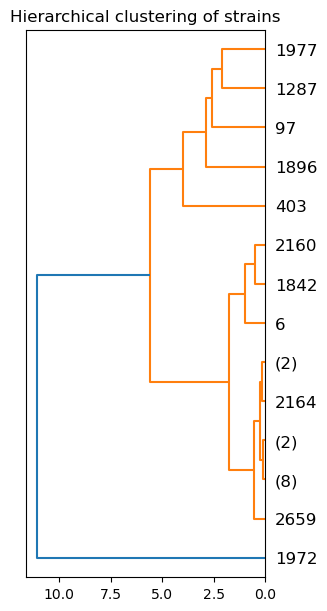

In [21]:
fig = plt.figure(figsize=(3,6), constrained_layout=True)
gs = fig.add_gridspec(1, 1)
ax = fig.add_subplot(gs[:,:])

ax.set_title("Hierarchical clustering of strains")

counts = np.zeros(model.children_.shape[0])
n_samples = len(model.labels_)
for i, merge in enumerate(model.children_):
    current_count = 0
    for child_idx in merge:
        if child_idx < n_samples:
            current_count += 1  # leaf node
        else:
            current_count += counts[child_idx - n_samples]
    counts[i] = current_count
linkage_matrix = np.column_stack( [model.children_, model.distances_, counts] ).astype(float)
dendrogram(linkage_matrix, truncate_mode="level", p=5, labels=clusters.index, orientation="left")

### SAVING
name = "{}/plot/clus_strn.png".format(cwd)
#plt.savefig(name, facecolor='w', edgecolor='w', transparent=False, bbox_inches="tight")
plt.show()

# Computing community composition UMAP

## Construct embedding

In [13]:
reducer = umap.UMAP(n_components=2, metric="euclidean")

In [14]:
X = freqs#.T

np.random.seed(4321)

embedding = reducer.fit_transform(X)
embedding = pd.DataFrame(embedding, index=X.index).reset_index()

## Assign cluster identity and other characteristics

In [17]:
# clustering of UMAP-reduced points

min_cluster_size = 10

cmap = mpl.colormaps["tab10"]
clustering = HDBSCAN(min_cluster_size = min_cluster_size)
embedding["clid"] = clustering.fit_predict(embedding[[0, 1]])
embedding["clus"] = embedding["clid"].apply(mpl.colormaps["tab10"])

# time in community-evolution days

cmap = mpl.colormaps["viridis"]
embedding["time"] = embedding["days"].apply(int)
embedding["time"] = embedding["time"].apply(lambda x: ( x - embedding["time"].min() ) / embedding["time"].max() )
embedding["time"] = embedding["time"].apply(lambda x: cmap(x))

cmap = mpl.colormaps["RdYlBu_r"]
# current [AMP] experienced
embedding["camp"] = embedding[["ablv", "days"]].apply(lambda x: 0 if not int(x.iloc[1]) in amps.index else amps.loc[int(x.iloc[1]), str(int(x.iloc[0]))], axis=1 )
embedding["camp"] = embedding["camp"].apply(lambda x: np.log(x + 1))
embedding["camp"] /= embedding["camp"].max()
embedding["camp"] = embedding["camp"].apply(lambda x: cmap(x))

# highest [AMP] experienced to date
embedding["expo"] = embedding[["ablv", "days"]].apply(lambda x: amps.loc[amps.index <= int(x.iloc[1]), str(int(x.iloc[0]))].max(), axis=1 )
embedding["expo"] = embedding["expo"].apply(lambda x: np.log(x + 1))
embedding["expo"] /= embedding["expo"].max()
embedding["expo"] = embedding["expo"].apply(lambda x: cmap(x))

In [18]:
# community-history
cmap = mpl.colormaps["coolwarm"]
embedding["chst"] = embedding["hist"].apply(lambda x: float(["ANC", "EVO"].index(x)) )
embedding["chst"] = embedding["chst"].apply(cmap)

# replicate
cmap = mpl.colormaps["tab10"]
embedding["crpl"] = embedding["repl"].apply(lambda x: float(x) / 10 )
embedding["crpl"] = embedding["crpl"].apply(cmap)

In [19]:
index = X.index.to_frame()

# partition codes
days_amps = np.full((71, 4), 3, dtype=int)
days_amps[:len(amps)][amps > 0] = 1
days_amps[:len(amps)][amps > 1] = 2
days_amps[:,0] = 0

# code attribution to indices
index["days"] = index["days"].apply(lambda x: int(x) - 1)
index["ablv"] = index["ablv"].apply(lambda x:  [0,5,50,500].index(x))

days_amps = days_amps[index["days"], index["ablv"]]

embedding["part"] = [ mpl.colormaps["tab10"](x / 10) for x in days_amps]

In [17]:
embedding.to_csv("{}/data/Comm_umap.csv".format(cwd), sep=",", index=False)

# UMAP plotting

## Define and pretreat plotting data

In [4]:
embedding = pd.read_csv("{}/data/Comm_umap.csv".format(cwd), )

for col in ["clus", "time", "camp", "expo", "chst", "crpl", "part"]:
    embedding[col] = embedding[col].apply(eval)

In [7]:
# defining cluster species pies

freq_clids = pd.read_csv("{}/data/Comm_umap.csv".format(cwd), header=[0], index_col=[0,1,2,3]).iloc[:,[0, 1, 2]]
pies = pd.concat([freqs, freq_clids.loc[:,"clid"], ], axis=1).set_index("clid", append=True).groupby("clid").mean()

# sorting strains by decreasing maximum frequency

pies.loc[("avg"),:] = pies.max(axis=0)
pies.sort_values(by = "avg", axis = 1, ascending = False, inplace = True)
pies.drop("avg", inplace = True)
pies = pies.loc[:, (pies != 0).any(axis=0)] # drop undetectable strains

# appending average coordinates

pies.index = pd.MultiIndex.from_frame(freq_clids.set_index("clid", append = True).groupby("clid").mean())

In [22]:
# table to be plotted

table = pd.DataFrame([["B", 105, 9, "+", "0", "", "++", "", ],
                      ["R", 14, 10, "", "+", "", "+", "+", ],
                      ["G", 1, 196, "", "+", "+", "+", "", ],
                      ["O", 104, 9, "", "0", "", "++", "+", ],
                      ],
                     index = ["B", "R", "G", "O", ],
                     columns = ["cluster", "nb ANC", "nb EVO", "97", "403", "1287", "1972", "1977"],
                     )

In [8]:
traits = {"clus": "cluster identity",
          "time": "experiment day (yellow = later)",
          "camp": r"[AMP]$_{(t)}$ (red = higher)",
          "crpl": "biological replicate",
          "chst": "history (blue = ANC)",
          "expo": r"[AMP]$_{\rm{max,}(t)}$ (red = higher)",
         }

## Plotting Fig. 2

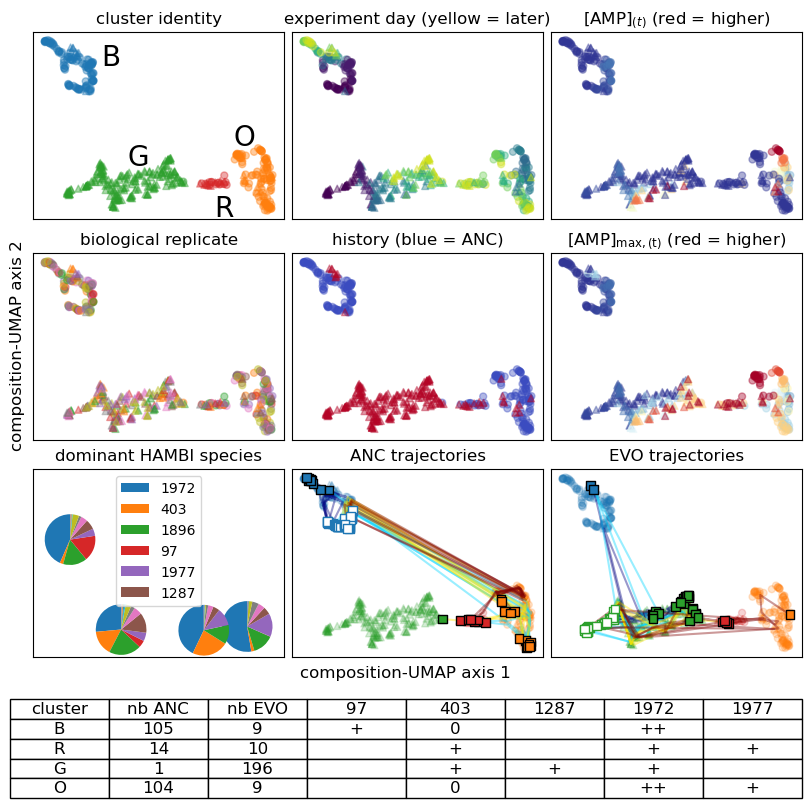

In [10]:
fig = plt.figure(figsize=(8,8), constrained_layout=True)

(subfig_t, subfig_b) = fig.subfigures(2, 1, height_ratios = [6,1]) # create top/bottom subfigs

gs = subfig_t.add_gridspec(3, 3)
subfig_t.supxlabel(r"composition-UMAP axis 1")
subfig_t.supylabel(r"composition-UMAP axis 2")

# cluster characteristics

for t, trait in enumerate(traits):
    
    ax = fig.add_subplot(gs[t // 3, t % 3])
    
    for h, hist in enumerate(embedding["hist"].unique()):
        df = embedding[embedding["hist"] == hist].copy()
        ax.scatter(df["0"], df["1"], c = df[trait], marker = ["o", "^"][h], s=25, alpha=0.4, )
    if t == 0:
        for i, idx in enumerate(pies.index):
            plt.text(idx[0] + [2,-2,0,0][i], idx[1] + [0,2,1,-2][i], ["B", "O", "G", "R", ][i], size = 20)
        
    ax.set(xticks = [], yticks = [], title = traits[trait], )

# pie charts

ax = fig.add_subplot(gs[2, 0])
labels = [strn if np.any(pies.loc[:,strn] >= 0.1) else "" for strn in pies.columns]
for i, idx in enumerate(pies.index):
    ax.pie(pies.loc[idx], center = idx, labels = labels if i == 0 else None, startangle=90, shadow=False, frame = True, radius = 2, labeldistance = None)
ax.axis("equal")  # Equal aspect ratio ensures that pie is drawn as a circle.
ax.legend()
ax.set(xticks = [], yticks = [], ylim = (6.7, 7.7), title = "dominant HAMBI species", )

# trajectories

for h, hist in enumerate(["ANC", "EVO"]):
    
    ax = fig.add_subplot(gs[2,h+1])
    ax.set(xticks = [], yticks = [], title = hist + " trajectories", )

    df = embedding[embedding["hist"] == hist]
    df = df[["hist", "ablv", "repl", "days", "0", "1"]].set_index(["hist", "ablv", "repl", "days"]).unstack()
    colrs = df.index.get_level_values("ablv")
    colrs = [sorted(list(colrs.unique())).index(x) / (len(colrs.unique()) - 1 ) for x in colrs]
    
    for i, idx in enumerate(df.index):
        ax.plot(df.loc[idx,"0"], df.loc[idx,"1"], zorder=2, alpha=0.4, c=mpl.colormaps["jet"](colrs[i]), )
        
    # clouds
    for h, hist2 in enumerate(embedding["hist"].unique()):
        df = embedding[embedding["hist"] == hist2].copy()
        ax.scatter(df["0"], df["1"], c = df["clus"], marker = ["o", "^"][h], s=25, alpha = 0.2, zorder=1)
        
    data = embedding[embedding["hist"] == hist].copy()
    for d, days in enumerate( [sorted(list(data["days"].unique()))[ddd] for ddd in [0, -1] ] ):
        df = data[data["days"] == days]
        ax.scatter(df["0"], df["1"], edgecolor = [df["clus"], "k"][d], facecolor=["w", df["clus"]][d], marker = "s", s=40, alpha = 1, zorder=3)

# table

ax = subfig_b.add_subplot()
TBL = plt.table(cellText = table.values, colLabels = table.columns,
                cellLoc = "center", loc = "center",
                edges = "BRTL",
               )
TBL.auto_set_font_size(False)
TBL.set_fontsize(12)
ax.xaxis.set_visible(False)
ax.yaxis.set_visible(False)
for v in ax.spines.values():
    v.set_visible(False)

### SAVING
name = "{}/plot/umap_freq.pdf".format(cwd)
plt.savefig(name, facecolor='w', edgecolor='w', transparent=False, bbox_inches="tight")
plt.show()